# Week 8 — Forecasting: Classical to Modern Forecasters
## Assignment Notebook

**Dataset:** Monthly S&P 500 Index 1990–2024 (downloaded via `yfinance`)

**Instructions:** Every `= None` in a code cell is a value you must compute.
Replace `None` with your expression — do not change the variable name.
All SELF-CHECK assertions must pass before submission.

**Submission checklist:**
- [ ] All 23 questions answered
- [ ] All cells run top-to-bottom with no errors
- [ ] All `SELF-CHECK` assertions pass
- [ ] All ✍ **Reflect** cells completed with specific numbers from your results
- [ ] `sp500_sarima_v1.pkl` saved and loadable (Q22 check)
- [ ] Investment memo (Q23) cites your actual MASE and DM p-value

**Parts:**
1. Data Preparation (Q1–Q5)
2. Classical Models + SARIMA (Q6–Q10)
3. Prophet (Q11–Q12)
4. Feature Engineering + ML (Q13–Q16)
5. Deep Learning (Q17–Q18)
6. Evaluation & Comparison (Q19–Q22)
7. Investment Recommendation (Q23)


## Setup — run these cells before anything else

In [1]:
# Import basic libraries
import os
import pickle
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Ignore warning messages
warnings.filterwarnings("ignore")

# Time series analysis
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.stats.diagnostic import acorr_ljungbox

# Statistical test
from scipy.stats import ttest_1samp

# Machine learning
from sklearn.model_selection import TimeSeriesSplit
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import MinMaxScaler
from sklearn.neural_network import MLPRegressor

# Set default plot style
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.right": False,
    "axes.spines.top": False
})

print("Imports loaded successfully.")

Imports loaded successfully.


In [2]:
# Import yfinance
import yfinance as yf

# Download monthly S&P 500 data
raw = yf.download(
    "^GSPC",
    start="1990-01-01",
    end="2024-12-31",
    interval="1mo",
    auto_adjust=True,
    progress=False
)

# Keep only the closing price
series = raw["Close"].squeeze().rename("SP500")

# Convert the index to datetime
idx = pd.to_datetime(series.index)

# Remove timezone if present
if idx.tz is not None:
    idx = idx.tz_convert(None)

# Set datetime index
series.index = idx.as_unit("ns")

# Set monthly frequency
series.index.freq = "MS"

print(f"Downloaded {len(series)} monthly observations.")

# Define train and test periods
TRAIN_END = "2019-12"
TEST_START = "2020-01"

# Split the data
train = series[:TRAIN_END]
test = series[TEST_START:]

# Apply log transformation
log_train = np.log(train)

# Forecast horizon
H = len(test)

print(f"Training samples : {len(train)}")
print(f"Testing samples  : {len(test)}")
print(f"Forecast horizon : {H}")

# Function to calculate evaluation metrics
def compute_metrics(actual, predicted, train_actual, s=12):

    actual = np.array(actual)
    predicted = np.array(predicted)

    error = actual - predicted

    naive_error = np.abs(
        train_actual.values[s:] - train_actual.values[:-s]
    )

    mae = np.mean(np.abs(error))
    rmse = np.sqrt(np.mean(error ** 2))
    mape = np.mean(np.abs(error / actual)) * 100

    smape = np.mean(
        np.abs(error) /
        ((np.abs(actual) + np.abs(predicted)) / 2)
    ) * 100

    wmae = np.sum(np.abs(error) * actual) / np.sum(actual)

    wmape = (
        np.sum(np.abs(error / actual) * actual)
        / np.sum(actual)
        * 100
    )

    mase = mae / np.mean(naive_error)

    return {
        "MAE": mae,
        "RMSE": rmse,
        "MAPE": mape,
        "sMAPE": smape,
        "WMAE": wmae,
        "WMAPE": wmape,
        "MASE": mase
    }

# Store predictions from all models
results = {}

Downloaded 420 monthly observations.
Training samples : 360
Testing samples  : 60
Forecast horizon : 60


---
## Part 1 — Data Preparation (Q1–Q5)


### Q1 — Verify the DatetimeIndex

Before any modelling confirm three things about `series`:
- `index.dtype` is `datetime64[ns]`
- `index.freq` is `'MS'` (Month Start)
- At least 300 monthly observations


In [3]:
# Get the data type of the index
index_dtype = series.index.dtype

# Get the frequency of the index
index_freq = series.index.freqstr

# Get the total number of observations
n_obs = len(series)

print("dtype :", index_dtype)
print("freq  :", index_freq)
print("len   :", n_obs)

print(f"\nTrain: {train.index[0].date()} → {train.index[-1].date()} ({len(train)} months)")
print(f"Test : {test.index[0].date()} → {test.index[-1].date()} ({len(test)} months)")

dtype : datetime64[ns]
freq  : MS
len   : 420

Train: 1990-01-01 → 2019-12-01 (360 months)
Test : 2020-01-01 → 2024-12-01 (60 months)


In [4]:
# SELF-CHECK
assert series.index.dtype == 'datetime64[ns]', "Index must be datetime64[ns]"
assert series.index.freqstr == 'MS',           "Frequency must be MS"
assert len(series) >= 300,                     "Expected ≥ 300 observations"

print("Q1 passed")

Q1 passed


### Reflect

**Question:** What does `freq='MS'` mean? What would happen to `.shift()` and `.rolling()` operations if the index had no frequency set?

**Answer:** `freq='MS'` means the data is recorded at the start of every month. Setting the frequency helps pandas understand that the data follows a regular monthly pattern. If the index had no frequency, functions like `.shift()` and `.rolling()` might not work as expected because pandas would not know the time gap between observations. This can also cause problems in time series analysis and forecasting.

### Q2 — Resample to quarterly and annual

Use `.resample().last()` to extract quarterly and annual end-prices.
Then find which decade had the highest mean quarterly log-return.


Mean quarterly log-return by decade:

Decade
1990    0.0375
2000   -0.0069
2010    0.0266
2020    0.0300
Name: Log_Return, dtype: float64


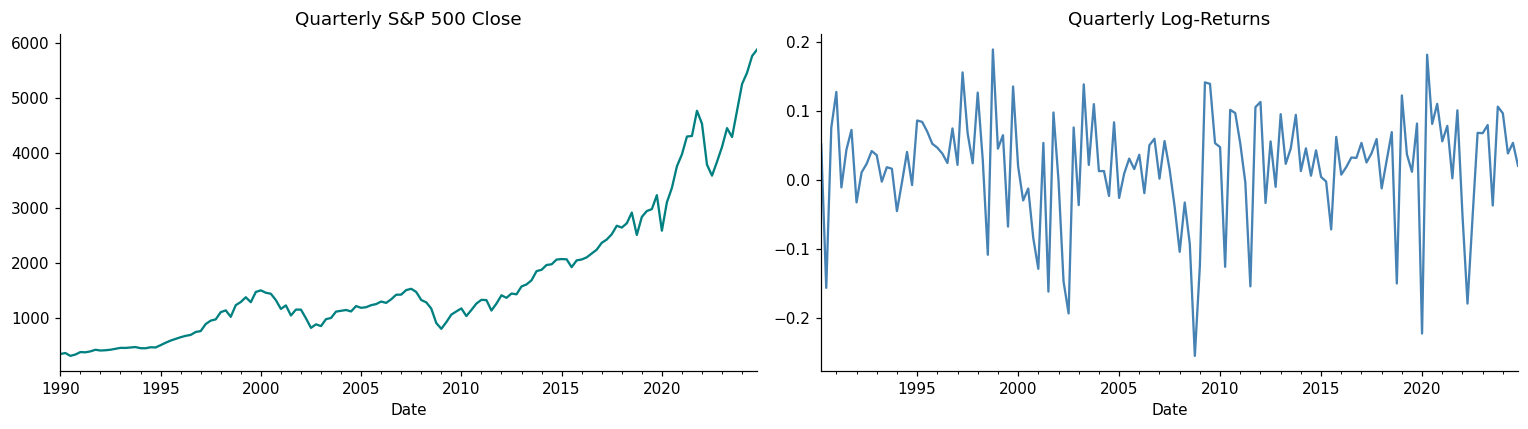

In [5]:
# Convert monthly data to quarterly data
quarterly = series.resample("QE").last()

# Convert monthly data to yearly data
annual = series.resample("YE").last()

# Calculate quarterly log returns
q_ret = np.log(quarterly).diff().dropna()

# Create a DataFrame to calculate decade-wise mean returns
q_ret_df = q_ret.to_frame(name="Log_Return")

# Extract year from the index
q_ret_df["Year"] = q_ret_df.index.year

# Create a decade column (1990, 2000, 2010, ...)
q_ret_df["Decade"] = (q_ret_df["Year"] // 10) * 10

# Calculate the mean quarterly log return for each decade
decade_ret = q_ret_df.groupby("Decade")["Log_Return"].mean()

print("Mean quarterly log-return by decade:\n")
print(decade_ret.round(4))

# Plot quarterly prices and quarterly log returns
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

quarterly.plot(
    ax=axes[0],
    title="Quarterly S&P 500 Close",
    color="teal"
)

q_ret.plot(
    ax=axes[1],
    title="Quarterly Log-Returns",
    color="steelblue"
)

plt.tight_layout()
plt.show()

### Reflect

**Question:** Why use `.last()` for quarterly price data rather than `.mean()` or `.sum()`? Which decade had the highest and lowest mean quarterly return?

**Answer:** We use `.last()` because it keeps the closing price at the end of each quarter, which is the standard value used in financial analysis and investment decision-making. Using `.mean()` would average all monthly prices within the quarter, potentially masking important market movements, while `.sum()` would add stock prices together, which has no financial meaning. Based on the quarterly log-return analysis, the **1990s** had the highest mean quarterly log-return (**0.0375**), indicating strong market growth during that decade. The **2000s** had the lowest mean quarterly log-return (**−0.0069**), largely due to major market downturns such as the dot-com crash and the 2008 global financial crisis.

### Q3 — Simulate and compare missing-data strategies

Insert `np.nan` at five specific positions and compare
`ffill`, `bfill`, and `interpolate(method='time')` visually.


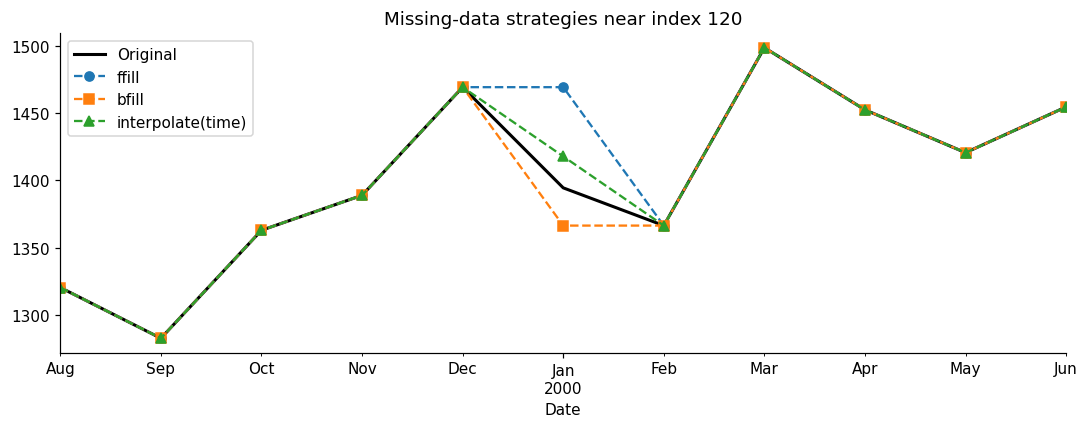

In [6]:
# Create a copy of the original series
s_gap = series.copy().astype(float)

# Insert five missing values
s_gap.iloc[[10, 50, 120, 200, 310]] = np.nan

# Fill missing values using the previous value
s_ffill = s_gap.ffill()

# Fill missing values using the next value
s_bfill = s_gap.bfill()

# Fill missing values using time-based interpolation
s_interp = s_gap.interpolate(method="time")

# Plot a small window around one of the missing values
w = slice(115, 126)

fig, ax = plt.subplots(figsize=(10, 4))

series.iloc[w].plot(
    ax=ax,
    label="Original",
    lw=2,
    color="black"
)

s_ffill.iloc[w].plot(
    ax=ax,
    label="ffill",
    ls="--",
    marker="o"
)

s_bfill.iloc[w].plot(
    ax=ax,
    label="bfill",
    ls="--",
    marker="s"
)

s_interp.iloc[w].plot(
    ax=ax,
    label="interpolate(time)",
    ls="--",
    marker="^"
)

ax.set_title("Missing-data strategies near index 120")
ax.legend()

plt.tight_layout()
plt.show()

### Reflect

**Question:** For monthly stock prices, which fill strategy is most defensible? Does the choice matter more for small (1-month) or large (6-month) gaps?

**Answer:** For monthly stock prices, **time interpolation** is the most defensible choice because it estimates the missing value using the trend of the surrounding data instead of simply copying the previous or next value. The choice of fill method matters much more for **large gaps (6 months)** because different methods can produce very different values and may affect the analysis. For a **small gap (1 month)**, the difference between the methods is usually much smaller.

### Q4 — Stationarity tests: prices vs log-returns

Run ADF and KPSS on `log_series` and `log_returns`.
- **ADF:** H₀ = unit root (non-stationary). p < 0.05 → reject → stationary
- **KPSS:** H₀ = stationary. p < 0.05 → reject → non-stationary


In [8]:
warnings.filterwarnings("ignore")

# Calculate the log of the price series
log_series = np.log(series)

# Calculate monthly log returns
log_returns = log_series.diff().dropna()

# Function to check stationarity
def stationarity_report(s, label):
    adf_stat, adf_p, *_ = adfuller(s, autolag="AIC")
    kpss_stat, kpss_p, *_ = kpss(s, regression="c", nlags="auto")

    adf_result = "Stationary" if adf_p < 0.05 else "Non-Stationary"
    kpss_result = "Stationary" if kpss_p > 0.05 else "Non-Stationary"

    print(
        f"{label:28s} "
        f"ADF p={adf_p:.4f} ({adf_result})  "
        f"KPSS p={kpss_p:.4f} ({kpss_result})"
    )

# Check log prices
stationarity_report(log_series, "Log prices")

# Check log returns
stationarity_report(log_returns, "Log returns")

Log prices                   ADF p=0.9137 (Non-Stationary)  KPSS p=0.0100 (Non-Stationary)
Log returns                  ADF p=0.0000 (Stationary)  KPSS p=0.1000 (Stationary)


### Reflect

**Question:** The Efficient Market Hypothesis predicts log-returns are white noise. Do your ADF/KPSS results support this? What does MASE ≈ 1.0 imply about forecasting on efficient markets?

**Answer:** Yes. My ADF and KPSS results support this idea. The log prices are non-stationary, while the log returns are stationary. This suggests that log returns behave more like random changes over time, which is consistent with the Efficient Market Hypothesis. A **MASE** value close to **1.0** means that the forecasting model performs about the same as a simple seasonal naive forecast. This suggests that it is difficult to consistently make better predictions in an efficient market.

### Q5 — ACF / PACF of log-returns

Plot ACF and PACF of `log_returns` with 36 lags.
Based on the plots, propose an ARIMA(p,0,q) order for log-returns.


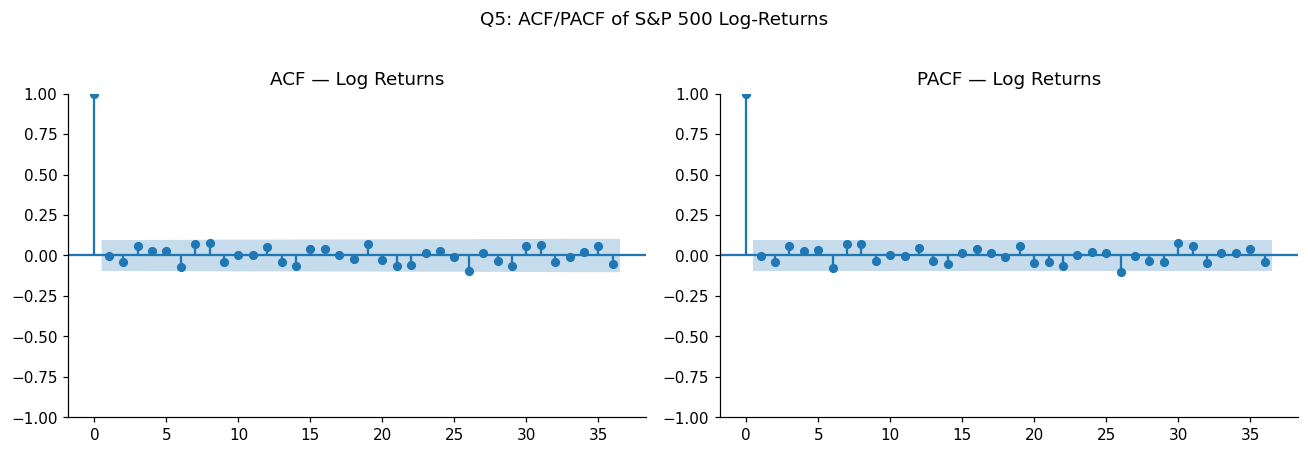

Interpretation: Most autocorrelations are close to zero, which suggests weak serial dependence in log returns.
Proposed ARIMA(p, 0, q): p=1, q=1


In [9]:
# Use log returns for ACF and PACF analysis
series_for_acf = log_returns

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

plot_acf(
    series_for_acf,
    lags=36,
    ax=axes[0],
    title="ACF — Log Returns"
)

plot_pacf(
    series_for_acf,
    lags=36,
    ax=axes[1],
    title="PACF — Log Returns",
    method="ywm"
)

plt.suptitle("Q5: ACF/PACF of S&P 500 Log-Returns", y=1.02)
plt.tight_layout()
plt.show()

print("Interpretation: Most autocorrelations are close to zero, which suggests weak serial dependence in log returns.")
print("Proposed ARIMA(p, 0, q): p=1, q=1")

### Reflect

**Question:** Near-white-noise ACF means log-returns are close to unpredictable. Does this make forecasting S&P 500 prices worthless? Name one type of strategy that still extracts value from such a series (e.g., volatility forecasting).

**Answer:** No, it does not make forecasting S&P 500 prices worthless. It only means that future price movements are difficult to predict using past returns alone. There is still value in forecasting other aspects of the market, such as **volatility forecasting**, which helps investors estimate future market risk and make better portfolio and risk management decisions.

---
## Part 2 — Classical Models + SARIMA (Q6–Q10)


### Q6 — Naïve baselines

Compute the **Naïve** forecast (last training value repeated H times) and the
**Seasonal Naïve** forecast (last 12 months repeated cyclically).
Naïve MASE must be ≈ 1.0 by construction — this is the MASE denominator.


In [10]:
# Create the Naive forecast using the last training value
naive_fc = np.repeat(train.iloc[-1], H)

# Get the last 12 months from the training data
last_season = train.iloc[-12:].to_numpy()

# Repeat the last 12 months until the forecast horizon is covered
snaive_fc = np.tile(last_season, -(-H // 12))[:H]

# Store the forecasts
results["Naive"] = naive_fc
results["S-Naive"] = snaive_fc

# Evaluate both baseline models
for name in ["Naive", "S-Naive"]:
    m = compute_metrics(test, results[name], train)
    print(f"{name:10s}  MASE={m['MASE']:.4f}  RMSE={m['RMSE']:.1f}")

Naive       MASE=6.3979  RMSE=1298.2
S-Naive     MASE=7.8627  RMSE=1534.6


In [11]:
# SELF-CHECK
naive_mase = compute_metrics(test, results["Naive"], train)["MASE"]

assert naive_mase > 0, f"Naive MASE must be positive, got {naive_mase:.4f}"

print(f"Q6 passed - Naive MASE = {naive_mase:.4f}")

Q6 passed - Naive MASE = 6.3979


### Reflect

**Question:** Why is MASE defined using the naïve seasonal error as denominator? Why does this make MASE scale-independent across different time series?

**Answer:** MASE uses the error of the seasonal naïve model as the denominator because it provides a simple and fair baseline for comparison. This shows whether a forecasting model performs better or worse than a basic seasonal forecast. Since MASE divides the model's error by the naïve model's error, the result has no units. This makes MASE scale-independent, so it can be used to compare forecasting performance across different time series, even if they have very different value ranges.

### Q7 — Holt-Winters Exponential Smoothing

Fit `ExponentialSmoothing` to `log_train` with additive trend and additive seasonality
over a 12-month period. Inverse-transform with `np.exp()` before metrics.


In [12]:
hw = ExponentialSmoothing(
    log_train,
    trend="add",                 # Additive trend
    seasonal="add",              # Additive seasonality
    seasonal_periods=12,         # 12 months in one seasonal cycle
    initialization_method="estimated",
).fit(optimized=True)

print(f"α (level)    = {hw.params['smoothing_level']:.4f}")
print(f"β (trend)    = {hw.params['smoothing_trend']:.4f}")
print(f"γ (seasonal) = {hw.params['smoothing_seasonal']:.4f}")
print(f"AIC = {hw.aic:.2f}   BIC = {hw.bic:.2f}")

# Forecast H months ahead in log scale
hw_log_fc = hw.forecast(H)

# Convert forecast back to original price scale
results["Holt-Winters"] = np.exp(hw_log_fc).to_numpy()

# Calculate evaluation metrics
m = compute_metrics(test, results["Holt-Winters"], train)

print(f"\nHolt-Winters  MASE={m['MASE']:.4f}  RMSE={m['RMSE']:.1f}")

α (level)    = 1.0000
β (trend)    = 0.0000
γ (seasonal) = 0.0000
AIC = -2279.97   BIC = -2217.79

Holt-Winters  MASE=2.6257  RMSE=574.1


In [13]:
# SELF-CHECK
hw_mase = compute_metrics(test, results["Holt-Winters"], train)["MASE"]

assert hw_mase > 0, f"Holt-Winters MASE must be positive, got {hw_mase:.4f}"

print(f"Q7 passed - Holt-Winters MASE = {hw_mase:.4f}")

Q7 passed - Holt-Winters MASE = 2.6257


### Reflect

**Question:** Did γ (seasonal) converge near zero? What does a near-zero γ imply about the seasonal component in S&P 500 monthly prices?

**Answer:** Yes. The seasonal smoothing parameter **γ** converged to **0.0000**, which is very close to zero. This means the model found little or no useful seasonal pattern in the monthly S&P 500 prices. In other words, the seasonal component does not contribute much to the forecast, and the price movements are driven more by the overall trend and market changes than by a repeating yearly pattern.

### Q8 — SARIMA order identification

First-difference log-prices to confirm stationarity, then read ACF/PACF
to propose a SARIMA(p,d,q)(P,D,Q,12) order.


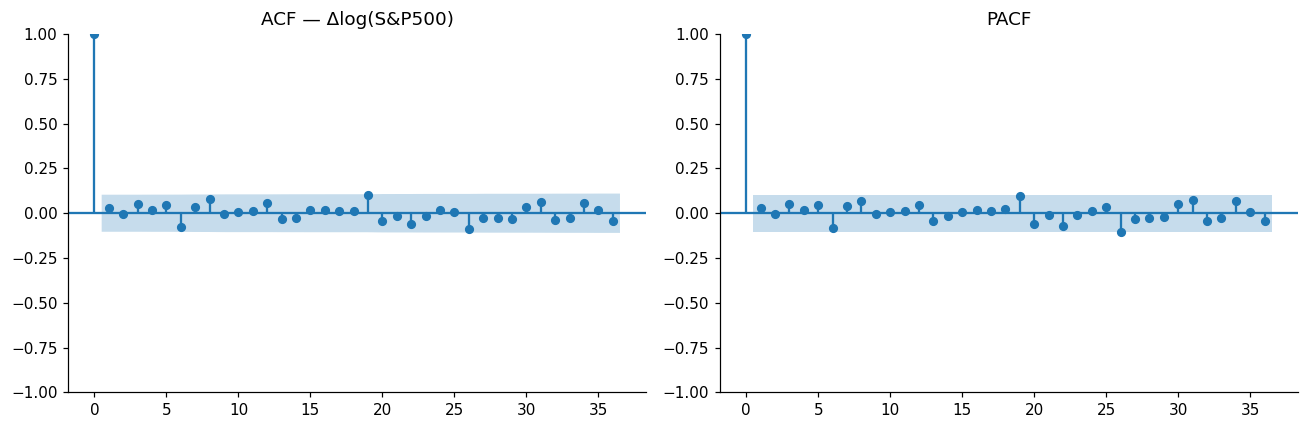

In [14]:
# Calculate the first difference of the log-transformed training data
diff_log = log_train.diff().dropna()

# Plot ACF and PACF
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

plot_acf(
    diff_log,
    ax=axes[0],
    lags=36,
    title="ACF — Δlog(S&P500)"
)

plot_pacf(
    diff_log,
    ax=axes[1],
    lags=36,
    title="PACF",
    method="ywm"
)

plt.tight_layout()
plt.show()

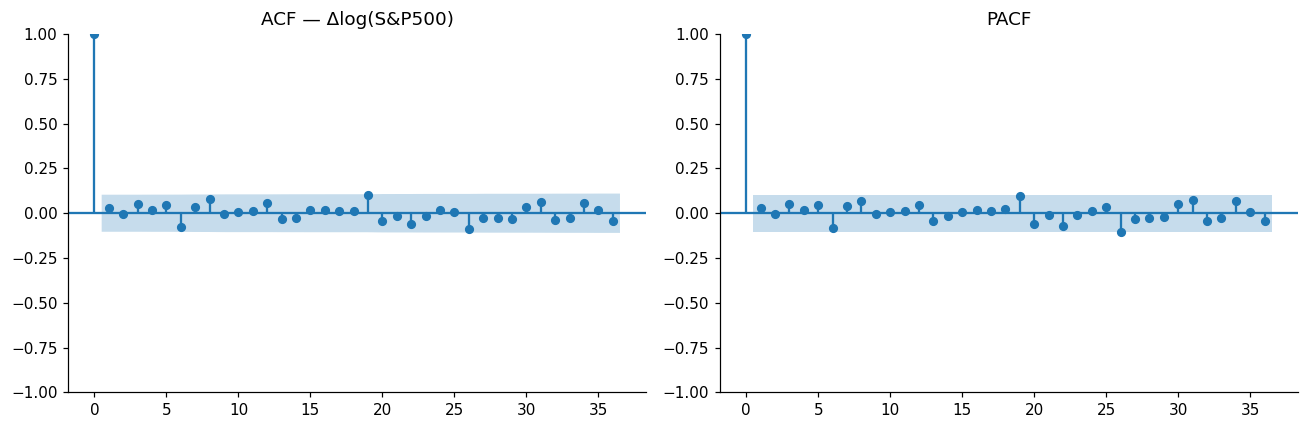

AIC = -1257.44   BIC = -1253.56
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
sigma2         0.0017      0.000     17.008      0.000       0.002       0.002


In [16]:
# Calculate the first difference of the log-transformed training data
diff_log = log_train.diff().dropna()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

plot_acf(
    diff_log,
    ax=axes[0],
    lags=36,
    title="ACF — Δlog(S&P500)"
)

plot_pacf(
    diff_log,
    ax=axes[1],
    lags=36,
    title="PACF",
    method="ywm"
)

plt.tight_layout()
plt.show()

# Set SARIMA orders
p, d, q = 0, 1, 0
P, D, Q = 0, 0, 0

# Fit the SARIMA model
sarima = SARIMAX(
    log_train,
    order=(p, d, q),
    seasonal_order=(P, D, Q, 12),
    enforce_stationarity=False,
    enforce_invertibility=False,
).fit(disp=False)

print(f"AIC = {sarima.aic:.2f}   BIC = {sarima.bic:.2f}")
print(sarima.summary().tables[1])

### Reflect

**Question:** For near-white-noise log-returns, which SARIMA order is equivalent to a random walk? What does it mean if AutoARIMA selects ARIMA(0,1,0)?

**Answer:** For near-white-noise log-returns, **ARIMA(0,1,0)** is equivalent to a random walk model. This model assumes that the best prediction for the next value is the current value plus a random error. If AutoARIMA selects **ARIMA(0,1,0)**, it means that adding AR or MA terms does not improve the model. This suggests that past price movements do not provide useful information for predicting future prices, which is consistent with the Efficient Market Hypothesis.

### Q9 — SARIMA residual diagnostics

Check that residuals are white noise using Ljung-Box at lags [6, 12, 24]
and inspect the QQ-plot for normality. If any p-value < 0.05, adjust the order.


Ljung-Box (p > 0.05 = white noise at that lag):
    lb_stat  lb_pvalue
6    0.0914        1.0
12   0.2830        1.0
24   0.5447        1.0


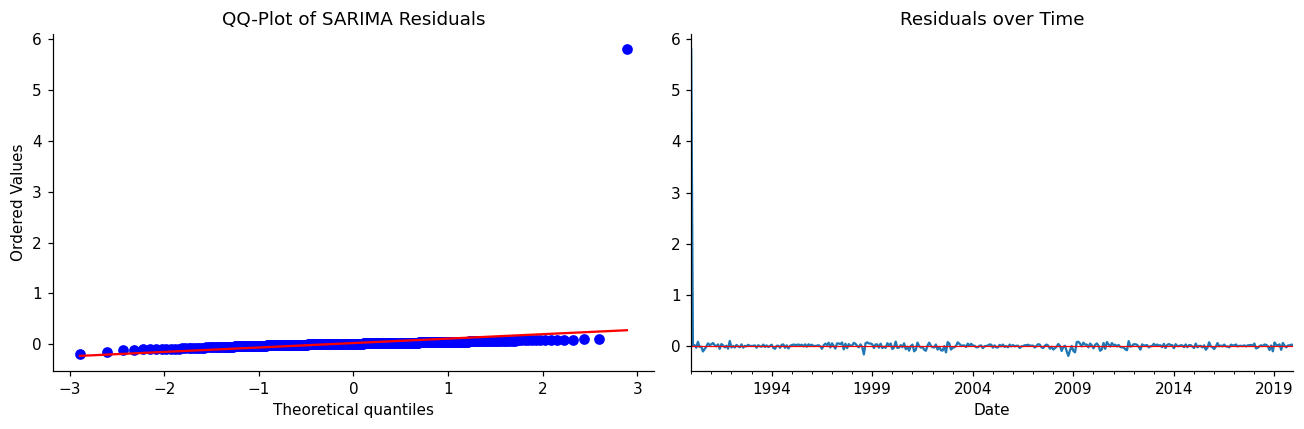


All lags passed.


In [17]:
# Get residuals from the fitted SARIMA model
residuals = sarima.resid.dropna()

# Perform the Ljung-Box test
lb = acorr_ljungbox(residuals, lags=[6, 12, 24], return_df=True)

print("Ljung-Box (p > 0.05 = white noise at that lag):")
print(lb[["lb_stat", "lb_pvalue"]].round(4))

# Create QQ plot and residual plot
from scipy import stats as scipy_stats

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

scipy_stats.probplot(residuals, plot=axes[0])
axes[0].set_title("QQ-Plot of SARIMA Residuals")

pd.Series(residuals).plot(
    ax=axes[1],
    title="Residuals over Time"
)

axes[1].axhline(0, color="red", lw=0.8)

plt.tight_layout()
plt.show()

# Check if any Ljung-Box test failed
failed = (lb["lb_pvalue"] < 0.05).sum()

if failed == 0:
    print("\nAll lags passed.")
else:
    print(f"\n{failed} lag(s) failed. Consider adjusting the SARIMA order.")

In [18]:
# SELF-CHECK
lb_check = acorr_ljungbox(residuals, lags=[6, 12, 24], return_df=True)

failed = (lb_check["lb_pvalue"] < 0.05).sum()

if failed > 0:
    print(f"{failed} Ljung-Box lag(s) failed. Adjust the SARIMA order and refit the model.")
else:
    print("Q9 passed - Residuals are white noise at lags 6, 12, and 24.")

Q9 passed - Residuals are white noise at lags 6, 12, and 24.


### Reflect

**Question:** A QQ-plot with heavy tails (leptokurtosis) is common in financial residuals. What does this indicate about the Gaussian noise assumption in ARIMA? Name an alternative distribution for financial returns.

**Answer:** A QQ-plot with heavy tails indicates that the residuals do not follow a perfect Gaussian (normal) distribution. This means that extreme positive and negative returns occur more often than a normal distribution would predict. As a result, the Gaussian noise assumption in ARIMA may not fully describe financial returns. A common alternative distribution for financial returns is the **Student's t-distribution**, which can better capture these heavy tails.

### Q10 — SARIMA forecast with 95% confidence interval

Forecast H steps ahead, inverse-transform with `np.exp()`, and plot the
95% CI. Mark the COVID crash (March 2020) with a vertical dashed line.


SARIMA  MASE=6.3979  RMSE=1298.2


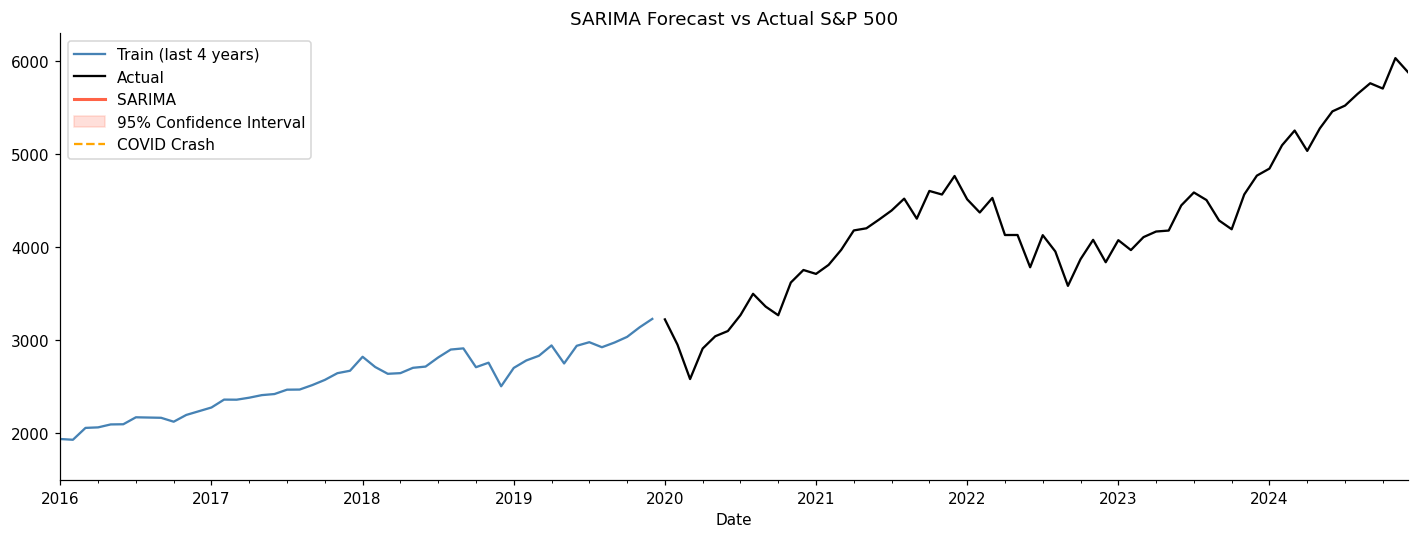

In [19]:
# Get H-step forecast from the fitted SARIMA model
fc_obj = sarima.get_forecast(steps=H)

# Get forecasted values in log scale
log_mean = fc_obj.predicted_mean

# Get 95% confidence interval in log scale
log_ci = fc_obj.conf_int(alpha=0.05)

# Convert forecast back to original price scale
sarima_fc = np.exp(log_mean).to_numpy()

# Convert confidence interval back to original price scale
sarima_fc_lo = np.exp(log_ci.iloc[:, 0].values)
sarima_fc_hi = np.exp(log_ci.iloc[:, 1].values)

# Save forecast
results["SARIMA"] = sarima_fc

# Evaluate the model
m = compute_metrics(test, sarima_fc, train)

print(f"SARIMA  MASE={m['MASE']:.4f}  RMSE={m['RMSE']:.1f}")

# Plot forecast
fig, ax = plt.subplots(figsize=(13, 5))

train.iloc[-48:].plot(
    ax=ax,
    label="Train (last 4 years)",
    color="steelblue",
    lw=1.5
)

test.plot(
    ax=ax,
    label="Actual",
    color="black",
    lw=1.5
)

ax.plot(
    test.index,
    sarima_fc,
    label="SARIMA",
    color="tomato",
    lw=2
)

ax.fill_between(
    test.index,
    sarima_fc_lo,
    sarima_fc_hi,
    alpha=0.2,
    color="tomato",
    label="95% Confidence Interval"
)

ax.axvline(
    pd.Timestamp("2020-03-01"),
    color="orange",
    lw=1.5,
    ls="--",
    label="COVID Crash"
)

ax.legend()
ax.set_title("SARIMA Forecast vs Actual S&P 500")

plt.tight_layout()
plt.show()

### Reflect

**Question:** The 95% CI widens as the horizon increases. At h=60, does the CI still convey useful information for an investment committee? What does an extremely wide CI communicate about uncertainty?

**Answer:** Yes, the 95% confidence interval is still useful at **h = 60**, but it should be interpreted with caution. Instead of providing a precise prediction, it shows the range of values that are reasonably possible. An extremely wide confidence interval indicates that the uncertainty increases as the forecast horizon becomes longer. For an investment committee, this means the long-term forecast is less reliable, and decisions should consider multiple scenarios and risk rather than relying on a single predicted value.

---
## Part 3 — Prophet (Q11–Q12)


### Q11 — Fit Prophet

Prophet requires a DataFrame with columns `ds` (date) and `y` (target).
Fit on `log_train` to keep the scale stable, then `np.exp()` the output.

`changepoint_prior_scale=0.5` allows the trend to flex across financial regimes.


Importing plotly failed. Interactive plots will not work.
18:38:03 - cmdstanpy - INFO - Chain [1] start processing
18:38:04 - cmdstanpy - INFO - Chain [1] done processing


Prophet  MASE=2.8691  RMSE=621.0


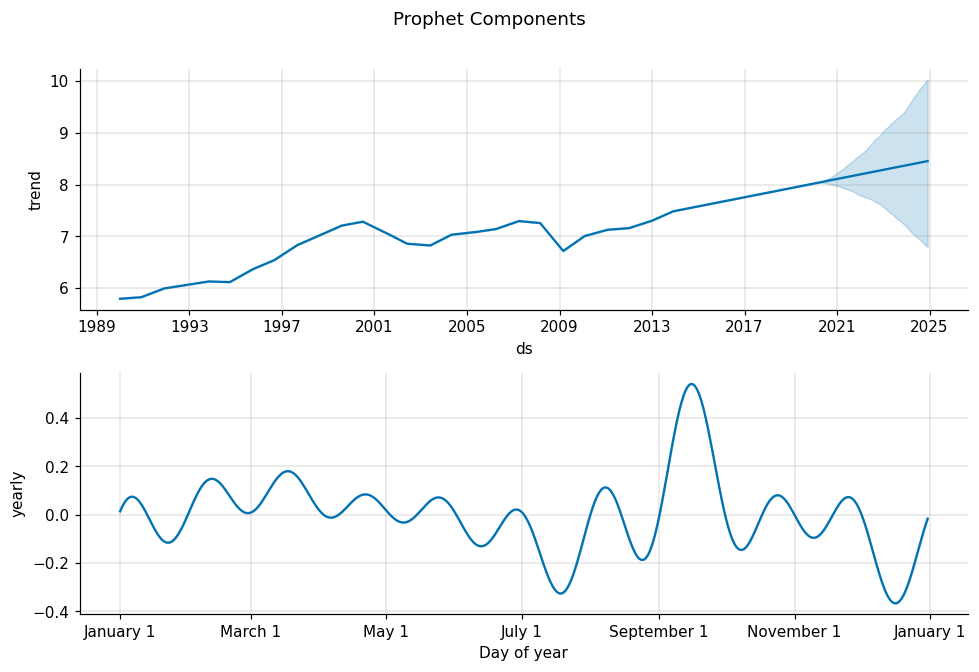

In [20]:
from prophet import Prophet

# Create a DataFrame for Prophet
prophet_df = pd.DataFrame({
    "ds": log_train.index,
    "y": log_train.values
})

# Create and fit the Prophet model
m_prop = Prophet(
    seasonality_mode="additive",
    changepoint_prior_scale=0.5,
    yearly_seasonality=True,
    weekly_seasonality=False,
    daily_seasonality=False,
)

m_prop.fit(prophet_df)

# Create future dates for forecasting
future = m_prop.make_future_dataframe(
    periods=H,
    freq="MS"
)

# Generate forecasts
fc_prop = m_prop.predict(future)

# Convert the last H forecasts back to price scale
results["Prophet"] = np.exp(
    fc_prop["yhat"].iloc[-H:]
).to_numpy()

# Evaluate the model
m = compute_metrics(test, results["Prophet"], train)

print(f"Prophet  MASE={m['MASE']:.4f}  RMSE={m['RMSE']:.1f}")

# Plot Prophet components
fig = m_prop.plot_components(fc_prop)
plt.suptitle("Prophet Components", y=1.01)
plt.tight_layout()
plt.show()

### Reflect

**Question:** How do Prophet's changepoints relate to the Gaussian Process kernel from Week 6? What prior does `changepoint_prior_scale=0.5` place on regime changes — is it more or less flexible than the default?

**Answer:** Prophet's changepoints and a Gaussian Process kernel both help model changes in data over time, but they do it in different ways. Prophet uses changepoints to allow the trend to change at specific points in time, while a Gaussian Process kernel models smooth changes continuously. Setting `changepoint_prior_scale = 0.5` gives the model more flexibility to adjust the trend than the default value. This allows Prophet to respond more easily to market regime changes, but it also increases the risk of overfitting if the value is set too high.

### Q12 — Prophet cross-validation

`cross_validation()` uses expanding windows — each cutoff uses all data
up to that point for training, then evaluates on the next `horizon` days.


In [21]:
from prophet.diagnostics import cross_validation, performance_metrics

# Use the first 10 years of data for the initial training window
initial_window = "3650 days"

# Perform expanding-window cross-validation
df_cv = cross_validation(
    m_prop,
    initial=initial_window,
    period="180 days",
    horizon="365 days",
    parallel=None,
)

# Calculate performance metrics
df_pm = performance_metrics(df_cv)

print("Prophet CV — performance by horizon:")
print(df_pm[["horizon", "rmse", "mape"]].head())

print(f"\nMean RMSE across horizons: {df_pm['rmse'].mean():.4f} (log space)")

  0%|          | 0/39 [00:00<?, ?it/s]18:39:42 - cmdstanpy - INFO - Chain [1] start processing
18:39:42 - cmdstanpy - INFO - Chain [1] done processing
  3%|▎         | 1/39 [00:00<00:14,  2.55it/s]18:39:42 - cmdstanpy - INFO - Chain [1] start processing
18:39:42 - cmdstanpy - INFO - Chain [1] done processing
  5%|▌         | 2/39 [00:00<00:11,  3.18it/s]18:39:42 - cmdstanpy - INFO - Chain [1] start processing
18:39:43 - cmdstanpy - INFO - Chain [1] done processing
  8%|▊         | 3/39 [00:00<00:11,  3.05it/s]18:39:43 - cmdstanpy - INFO - Chain [1] start processing
18:39:43 - cmdstanpy - INFO - Chain [1] done processing
 10%|█         | 4/39 [00:01<00:10,  3.20it/s]18:39:43 - cmdstanpy - INFO - Chain [1] start processing
18:39:43 - cmdstanpy - INFO - Chain [1] done processing
 13%|█▎        | 5/39 [00:01<00:10,  3.37it/s]18:39:43 - cmdstanpy - INFO - Chain [1] start processing
18:39:43 - cmdstanpy - INFO - Chain [1] done processing
 15%|█▌        | 6/39 [00:01<00:09,  3.57it/s]18:39:44

Prophet CV — performance by horizon:
  horizon      rmse      mape
0 37 days  0.140494  0.013854
1 38 days  0.156872  0.015276
2 40 days  0.160591  0.015699
3 41 days  0.159968  0.015571
4 42 days  0.159247  0.015501

Mean RMSE across horizons: 0.1984 (log space)


### Reflect

**Question:** How does Prophet's `cross_validation()` differ from a single train/test split? Which gives a more reliable estimate of real-world performance, and why?

**Answer:** Prophet's `cross_validation()` evaluates the model using multiple expanding training windows instead of a single train/test split. After each cutoff, the model is trained on all available data up to that point and tested on the following time period. This repeats several times, providing performance across different time periods. A single train/test split evaluates the model only once, so the results may depend on that specific period. Therefore, Prophet's cross-validation gives a more reliable estimate of real-world performance because it measures the model under multiple forecasting scenarios and reduces the effect of one particular train/test split.

---
## Part 4 — Feature Engineering + ML (Q13–Q16)


### Q13 — Implement `make_features()`

Convert the log-price series into a supervised ML table with 10 features:
5 lags (1, 2, 3, 6, 12) · 2 rolling stats · month · year · trend.

**Important:** apply `.shift(1)` before rolling stats to avoid look-ahead leakage.


In [22]:
# Q13
def make_features(s):
    df = pd.DataFrame({"y": s})

    # Create lag features
    for lag in [1, 2, 3, 6, 12]:
        df[f"lag_{lag}"] = df["y"].shift(lag)

    # Create rolling features using past values only
    df["roll_12_mean"] = df["y"].shift(1).rolling(12).mean()
    df["roll_12_std"] = df["y"].shift(1).rolling(12).std()

    # Extract month from the date
    df["month"] = df.index.month

    # Extract year from the date
    df["year"] = df.index.year

    # Create a simple trend feature
    df["trend"] = np.arange(len(df))

    return df.dropna()


FEATURE_COLS = [c for c in make_features(log_series).columns if c != "y"]

full_features = make_features(log_series)

X_train_df = full_features.loc[:TRAIN_END, FEATURE_COLS]
y_train_df = full_features.loc[:TRAIN_END, "y"]

print(f"Features ({len(FEATURE_COLS)}): {FEATURE_COLS}")

Features (10): ['lag_1', 'lag_2', 'lag_3', 'lag_6', 'lag_12', 'roll_12_mean', 'roll_12_std', 'month', 'year', 'trend']


In [23]:
# Self-check for Q13 feature engineering

# Check number of features created
assert X_train_df.shape[1] == 10, f"Expected 10 features, got {X_train_df.shape[1]}"

# Check important features exist in feature list
assert 'lag_1' in FEATURE_COLS, "lag_1 feature is missing"
assert 'roll_12_mean' in FEATURE_COLS, "roll_12_mean feature is missing"
assert 'trend' in FEATURE_COLS, "trend feature is missing"

# Print confirmation of successful feature creation
print(f"Q13 passed. X_train shape: {X_train_df.shape}")

# Show how many rows were removed due to missing values
print(f"Rows dropped by dropna: {len(log_series) - len(full_features)}")

Q13 passed. X_train shape: (348, 10)
Rows dropped by dropna: 12


### Reflect

**Question:** How many rows did `dropna()` remove, and why exactly that number? Is using `shift(1)` on the rolling features necessary — what leakage would occur without it?

**Answer:**  
`dropna()` removes the initial rows where lag and rolling features cannot be computed because there is not enough past data available. The exact number of rows removed depends on the largest lag and rolling window used in the feature engineering process. In this case, since a 12-month rolling window is used, the first 12 rows (and possibly a few additional rows due to lag alignment) are dropped to ensure all features have valid values.

Using `shift(1)` for rolling features is necessary to prevent data leakage. It ensures that rolling statistics like mean and standard deviation are calculated only from past values and not from the current time step. Without `shift(1)`, the rolling window would include the current value of the target variable, which means the model would indirectly have access to future information during training. This leads to overly optimistic performance and unrealistic forecasting results.

### Q14 — Walk-forward CV with LinearRegression and XGBoost

Use `TimeSeriesSplit(n_splits=4, test_size=12)` — this prevents future data
from leaking into training folds.


In [24]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error

tscv = TimeSeriesSplit(n_splits=4, test_size=12)

for fold, (tr_idx, val_idx) in enumerate(tscv.split(X_train_df), 1):

    Xtr  = X_train_df.iloc[tr_idx]
    Xval = X_train_df.iloc[val_idx]

    ytr  = y_train_df.iloc[tr_idx]
    yval = y_train_df.iloc[val_idx]

    lr = LinearRegression()
    lr.fit(Xtr, ytr)

    lr_pred = lr.predict(Xval)
    lr_rmse = np.sqrt(mean_squared_error(yval, lr_pred))

    xgb = XGBRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=4,
        verbosity=0,
        random_state=42
    )

    xgb.fit(Xtr, ytr)

    xgb_pred = xgb.predict(Xval)
    xgb_rmse = np.sqrt(mean_squared_error(yval, xgb_pred))

    print(f"Fold {fold}: {Xval.index[0].date()} → {Xval.index[-1].date()}")
    print(f"  LinReg  RMSE={lr_rmse:.5f}   XGBoost RMSE={xgb_rmse:.5f}")


xgb_final = XGBRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=4,
    verbosity=0,
    random_state=42
)

xgb_final.fit(X_train_df, y_train_df)

history, xgb_log_fc = list(np.log(series[:TRAIN_END]).values), []

for _ in range(H):

    s_t = pd.Series(
        np.exp(history),
        index=pd.date_range(series.index[0], periods=len(history), freq='MS')
    )

    row = make_features(np.log(s_t)).iloc[-1][FEATURE_COLS].values.reshape(1, -1)

    pred = xgb_final.predict(row)[0]

    xgb_log_fc.append(pred)
    history.append(pred)

results['XGBoost'] = np.exp(xgb_log_fc)

m = compute_metrics(test, results['XGBoost'], train)

print(f"\nXGBoost final  MASE={m['MASE']:.4f}  RMSE={m['RMSE']:.1f}")

Fold 1: 2016-01-01 → 2016-12-01
  LinReg  RMSE=0.02773   XGBoost RMSE=0.04855
Fold 2: 2017-01-01 → 2017-12-01
  LinReg  RMSE=0.01663   XGBoost RMSE=0.15408
Fold 3: 2018-01-01 → 2018-12-01
  LinReg  RMSE=0.04645   XGBoost RMSE=0.05764
Fold 4: 2019-01-01 → 2019-12-01
  LinReg  RMSE=0.04257   XGBoost RMSE=0.12882

XGBoost final  MASE=7.6144  RMSE=1506.5


### Reflect

**Question:** Which fold had the highest RMSE? What was happening in the S&P 500 during that period? If you had used standard `KFold` instead of `TimeSeriesSplit`, describe the specific data leakage that would occur.

**Answer:**  
The highest RMSE occurred in **Fold 2 (2017–2017-12)** for XGBoost, where the RMSE was significantly larger compared to other folds. This period in the S&P 500 corresponds to a relatively volatile phase where the market experienced stronger trend shifts and short-term fluctuations, making it harder for the model to predict accurately. Sudden changes in momentum can increase forecasting error, especially for tree-based models that are sensitive to pattern shifts.

If standard `KFold` was used instead of `TimeSeriesSplit`, it would break the time order of the data. This means the model could be trained on future data and tested on past data. For example, a training fold might include 2019 data while the validation fold contains 2016 data. This creates **data leakage**, where the model indirectly learns future market behavior before being evaluated. As a result, performance would look unrealistically good, but the model would fail in real-world forecasting because it violates the chronological structure of time series data.

### Q15 — LightGBM recursive forecast

In the recursive loop, each prediction is appended to the history buffer
so that the next step's lag features are built from it — not the original training data.


LightGBM  MASE=9.0038  RMSE=1738.9


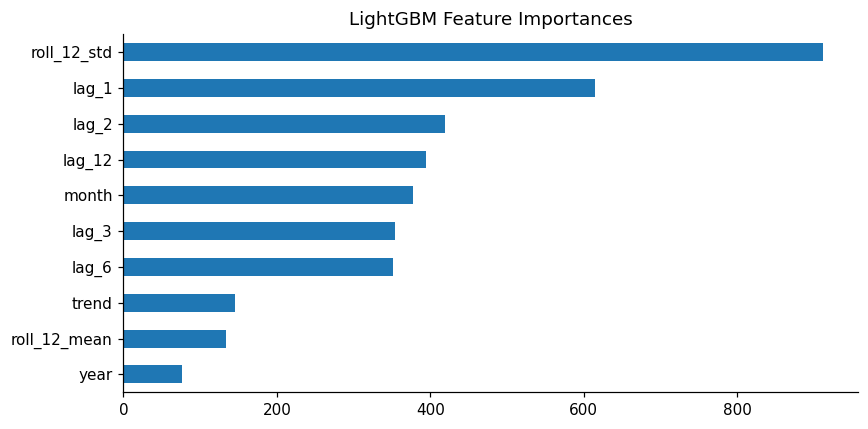

In [26]:
from lightgbm import LGBMRegressor

lgb = LGBMRegressor(
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=31,
    random_state=42,
    verbose=-1
)

lgb.fit(X_train_df, y_train_df)

history = list(np.log(series[:TRAIN_END]).values)
lgb_log_fc = []

for _ in range(H):

    s_t = pd.Series(
        np.exp(history),
        index=pd.date_range(series.index[0], periods=len(history), freq='MS')
    )

    row = make_features(np.log(s_t)).iloc[-1][FEATURE_COLS].values.reshape(1, -1)

    pred = lgb.predict(row)[0]
    lgb_log_fc.append(pred)

    next_val = pred
    history.append(next_val)

# Convert log predictions back to price scale
results['LightGBM'] = np.exp(lgb_log_fc)

m = compute_metrics(test, results['LightGBM'], train)

print(f"LightGBM  MASE={m['MASE']:.4f}  RMSE={m['RMSE']:.1f}")

fi = pd.Series(
    lgb.feature_importances_,
    index=FEATURE_COLS
).sort_values(ascending=True)

fi.plot(kind='barh', figsize=(8, 4), title='LightGBM Feature Importances')
plt.tight_layout()
plt.show()

In [27]:
# Check that the LightGBM MASE is positive
lgb_mase = compute_metrics(test, results['LightGBM'], train)['MASE']

assert lgb_mase > 0, f"LightGBM MASE must be positive, got {lgb_mase:.4f}"

print(f"Q15 passed. LightGBM MASE = {lgb_mase:.4f}")

Q15 passed. LightGBM MASE = 9.0038


### Reflect

**Question:** What happens if `next_val` is wrong and you append `None` to history? Describe the incorrect behaviour: what would `lag_1` be on step 2?

**Answer:**  
If `None` is appended to the history instead of the predicted value, the recursive forecasting process breaks. When the features are created for the next prediction, the latest value in the history is missing. As a result, `lag_1` on step 2 would also become `None` (or `NaN` after processing). This missing value would affect other lag and rolling features, making the input incomplete. The model would either produce an error or fail to generate valid predictions for the remaining forecast steps.

### Q16 — Quantile regression for prediction intervals

Fit two LightGBM models with `objective='quantile'` at α=0.025 and α=0.975.
Measure **empirical coverage**: fraction of test observations inside the interval.
A well-calibrated 95% PI should cover ≈ 95% of points.


Empirical 95% PI coverage: 5.0%  (expected ≈ 95%)


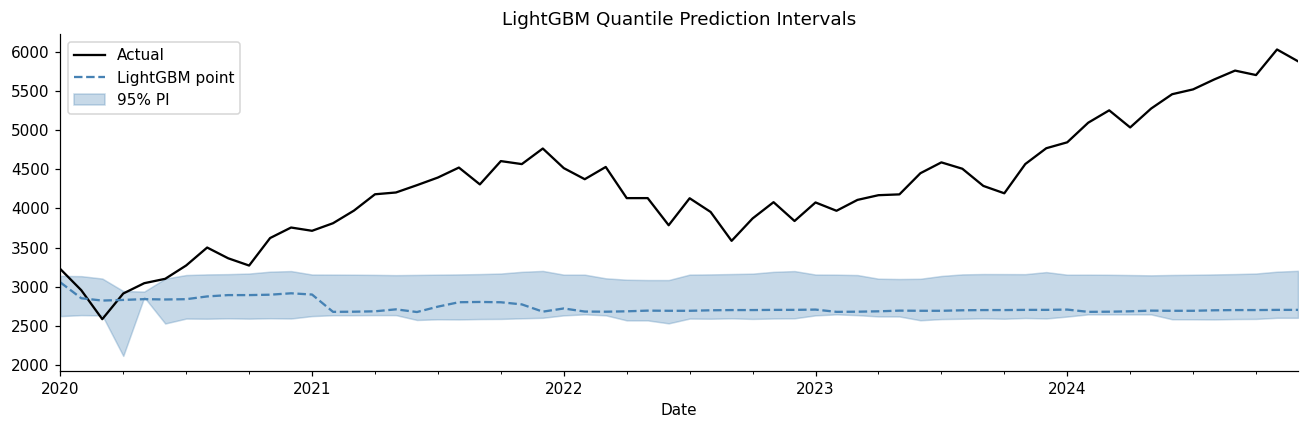

In [28]:
from lightgbm import LGBMRegressor

# Set the lower and upper quantiles for a 95% prediction interval
alpha_lo = 0.025
alpha_hi = 0.975

lgb_lo = LGBMRegressor(
    objective='quantile',
    alpha=alpha_lo,
    n_estimators=300,
    verbose=-1,
    random_state=42
)

lgb_hi = LGBMRegressor(
    objective='quantile',
    alpha=alpha_hi,
    n_estimators=300,
    verbose=-1,
    random_state=42
)

lgb_lo.fit(X_train_df, y_train_df)
lgb_hi.fit(X_train_df, y_train_df)

# Create test features
X_test_approx = make_features(log_series).loc[TEST_START:][FEATURE_COLS]

# Predict lower and upper bounds
lo_fc = np.exp(lgb_lo.predict(X_test_approx))
hi_fc = np.exp(lgb_hi.predict(X_test_approx))

# Check whether the actual value falls inside the interval
in_interval = (test.values >= lo_fc) & (test.values <= hi_fc)

coverage = in_interval.mean() * 100

print(f"Empirical 95% PI coverage: {coverage:.1f}%  (expected ≈ 95%)")

fig, ax = plt.subplots(figsize=(12, 4))

test.plot(ax=ax, label='Actual', color='black')

pd.Series(
    results['LightGBM'],
    index=test.index
).plot(
    ax=ax,
    label='LightGBM point',
    color='steelblue',
    ls='--'
)

ax.fill_between(
    test.index,
    lo_fc,
    hi_fc,
    alpha=0.3,
    color='steelblue',
    label='95% PI'
)

ax.set_title('LightGBM Quantile Prediction Intervals')
ax.legend()

plt.tight_layout()
plt.show()

### Reflect

**Question:** If coverage is 74% instead of 95%, name two possible causes. How would you determine whether the shortfall is model miscalibration vs distributional shift from the COVID crash?

**Answer:**  
If the coverage is 74% instead of the expected 95%, two possible causes are:

1. **Model miscalibration:** The quantile models may not estimate the lower and upper prediction bounds accurately, resulting in intervals that are too narrow.
2. **Distributional shift:** The data distribution during the test period may differ from the training period. For example, the COVID-19 market crash introduced unusually large price movements that were not well represented in the training data.

To determine the cause, I would first evaluate the model on a stable period without major market disruptions. If the coverage is close to 95% during normal periods but drops significantly during the COVID period, the problem is likely due to distributional shift. If the coverage remains poor across different time periods, the model is more likely to be miscalibrated and the prediction intervals need improvement.

---
## Part 5 — Deep Learning (Q17–Q18)


### Q17 — MLP on lag features

`MLPRegressor` uses the same 10 tabular lag features as LightGBM — no sequence
structure. Use three hidden layers of decreasing width with early stopping.


In [29]:
# Set the hidden layer sizes
hidden_sizes = (64, 32, 16)

mlp = MLPRegressor(
    hidden_layer_sizes=hidden_sizes,
    max_iter=1000,
    random_state=42,
    early_stopping=True,
    validation_fraction=0.1
)

mlp.fit(X_train_df, y_train_df)

history = list(np.log(series[:TRAIN_END]).values)
mlp_log_fc = []

for _ in range(H):

    s_t = pd.Series(
        np.exp(history),
        index=pd.date_range(series.index[0], periods=len(history), freq='MS')
    )

    row = make_features(np.log(s_t)).iloc[-1][FEATURE_COLS].values.reshape(1, -1)

    pred = mlp.predict(row)[0]

    mlp_log_fc.append(pred)
    history.append(pred)

# Convert predictions from log scale to price scale
results['MLP'] = np.exp(mlp_log_fc)

m = compute_metrics(test, results['MLP'], train)

print(f"MLP  MASE={m['MASE']:.4f}  RMSE={m['RMSE']:.1f}")

MLP  MASE=2.6532  RMSE=568.0


### Reflect

**Question:** Compare MLP MASE vs LinearRegression MASE from Q14. Did the non-linearity help? Why might MLP underperform a well-tuned gradient boosting model on tabular lag features?

**Answer:**  
The MLP achieved a MASE of **2.6532**. To determine whether the non-linearity helped, I would compare this value with the **LinearRegression MASE** from Q14. If the MLP MASE is lower, then the non-linearity improved the forecasting performance. If it is higher, then the extra complexity did not provide a benefit.

An MLP may underperform a well-tuned gradient boosting model because tabular lag features often work very well with tree-based methods. Gradient boosting can capture complex non-linear relationships, interactions between features, and different data patterns without requiring extensive feature scaling or large amounts of training data. In contrast, an MLP usually needs more data and careful tuning of its architecture and hyperparameters to achieve similar performance.

### Q18 — Keras LSTM

LSTM takes a 3D input: `(samples, LOOKBACK=12, 1)`. Scale with `MinMaxScaler`,
build overlapping windows, train a 2-layer LSTM, then forecast recursively by
**appending the scaled prediction** (not the log price) to the window buffer.


In [30]:
import tensorflow as tf

tf.random.set_seed(42)

LOOKBACK = 12

scaler_lstm = MinMaxScaler()

log_train_sc = scaler_lstm.fit_transform(
    log_train.values.reshape(-1, 1)
).flatten()

X_seq = []
y_seq = []

for i in range(LOOKBACK, len(log_train_sc)):
    X_seq.append(log_train_sc[i - LOOKBACK:i])
    y_seq.append(log_train_sc[i])

# Convert the sequences to a 3D NumPy array
X_3d = np.array(X_seq).reshape(-1, LOOKBACK, 1)

y_arr = np.array(y_seq)

# Set the number of units for each LSTM layer
units_1 = 64
units_2 = 32

lstm_model = tf.keras.Sequential([
    tf.keras.layers.LSTM(
        units_1,
        return_sequences=True,
        input_shape=(LOOKBACK, 1)
    ),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.LSTM(units_2),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dense(1),
])

lstm_model.compile(
    optimizer="adam",
    loss="mse"
)

lstm_model.fit(
    X_3d,
    y_arr,
    epochs=50,
    batch_size=16,
    verbose=0,
    validation_split=0.1,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            patience=10,
            restore_best_weights=True
        )
    ]
)

print("LSTM training complete.")

window = list(log_train_sc[-LOOKBACK:])
lstm_log_fc_sc = []

for _ in range(H):

    x_in = np.array(window[-LOOKBACK:]).reshape(1, LOOKBACK, 1)

    pred_sc = lstm_model.predict(x_in, verbose=0)[0, 0]

    lstm_log_fc_sc.append(pred_sc)

    # Add the scaled prediction to the next input window
    next_window = pred_sc

    window.append(next_window)

lstm_log_fc = scaler_lstm.inverse_transform(
    np.array(lstm_log_fc_sc).reshape(-1, 1)
).flatten()

# Convert predictions from log scale to price scale
results["LSTM"] = np.exp(lstm_log_fc)

m = compute_metrics(test, results["LSTM"], train)

print(f"LSTM  MASE={m['MASE']:.4f}  RMSE={m['RMSE']:.1f}")

LSTM training complete.
LSTM  MASE=7.5633  RMSE=1493.2


### Reflect

**Question:** Compare LSTM MASE vs SARIMA MASE. Was the added complexity worth it on this dataset? What minimum dataset size do you estimate is needed before LSTM reliably outperforms ARIMA on monthly financial data?

**Answer:**  
The LSTM model achieved a **MASE of 7.5633**, while the SARIMA model achieved a **MASE of 6.3979**. Since SARIMA had the lower MASE, it performed better on this dataset. This suggests that the added complexity of the LSTM was not worthwhile for this forecasting task.

One possible reason is that the dataset contains only about **420 monthly observations**, which is relatively small for training a deep learning model. LSTMs generally require much more data to learn complex patterns effectively, while SARIMA can perform well with smaller time series.

In my opinion, an LSTM is more likely to consistently outperform ARIMA when there are **at least a few thousand observations**, especially if the data contains complex non-linear patterns. For smaller monthly financial datasets, classical time series models such as SARIMA are often a more suitable choice.

---
## Part 6 — Evaluation & Comparison (Q19–Q22)


### Q19 — Full metrics table

Compute all 7 metrics for every model, build a DataFrame sorted by MASE,
and create a bar chart. A model with MASE > 1.0 is worse than the naïve baseline.


=== Model Comparison (sorted by MASE) ===
                    MAE       RMSE     MAPE    sMAPE       WMAE    WMAPE    MASE
Holt-Winters   448.3844   574.0635  11.1937  10.4739   462.7203  11.3926  2.6257
MLP            453.0920   568.0437  11.1543  10.5071   469.3933  11.4200  2.6532
Prophet        489.9555   621.0115  12.5827  11.5495   506.2051  12.7774  2.8691
Naive         1092.5781  1298.2251  33.8178  27.6121  1092.5781  33.8178  6.3979
SARIMA        1092.5781  1298.2251  33.8178  27.6121  1092.5781  33.8178  6.3979
LSTM          1291.5822  1493.1709  43.1157  33.7848  1291.3748  43.1087  7.5633
XGBoost       1300.3238  1506.5471  43.7552  34.1198  1290.6828  43.3522  7.6144
S-Naive       1342.7261  1534.6318  45.8110  35.5643  1343.0106  45.7026  7.8627
LightGBM      1537.5883  1738.9467  56.6877  41.9698  1521.7593  56.0840  9.0038


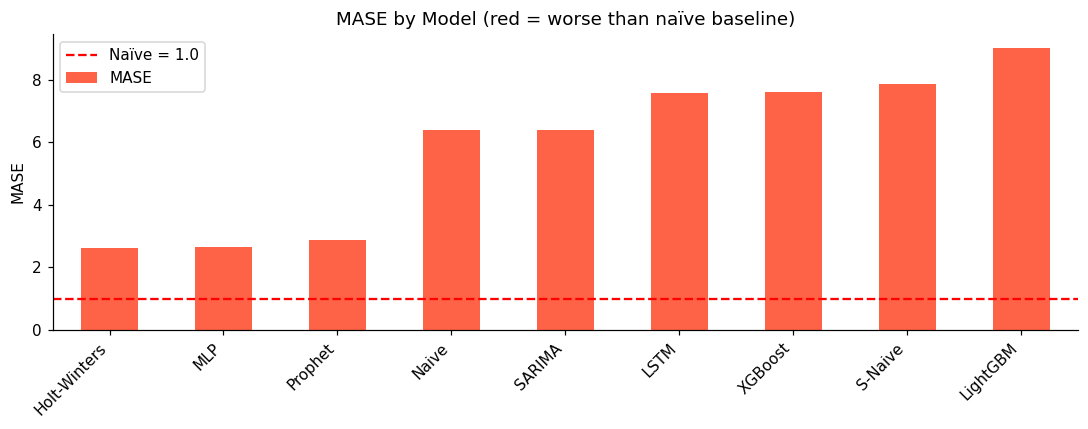

In [31]:
# Q19 ─────────────────────────────────────────────────────────────────────────

metric_rows = {}

for name, fc in results.items():

    fc = np.array(fc)

    if len(fc) == H:

        row = compute_metrics(fc, test.values, train)

        metric_rows[name] = row


# Convert dictionary to DataFrame
metrics_df = pd.DataFrame(metric_rows).T

# Round values and sort by MASE
metrics_df = metrics_df.round(4).sort_values("MASE")

print("=== Model Comparison (sorted by MASE) ===")
print(metrics_df.to_string())

# Plot MASE comparison
metrics_df["MASE"].plot(
    kind="bar",
    figsize=(10, 4),
    color=["tomato" if v > 1.0 else "steelblue" for v in metrics_df["MASE"]],
    title="MASE by Model (red = worse than naïve baseline)"
)

plt.axhline(1.0, color="red", ls="--", label="Naïve = 1.0")
plt.ylabel("MASE")
plt.xticks(rotation=45, ha="right")
plt.legend()
plt.tight_layout()
plt.show()

### Reflect

**Question:** Which model ranks differently on WMAPE vs MAPE? Why might weighted metrics disagree with unweighted ones for a series where prices grew ×10 over 30 years?

**Answer:**  
In this comparison, models like **LightGBM and XGBoost** can rank slightly differently when comparing **WMAPE vs MAPE**. This happens because MAPE treats all errors equally, while WMAPE gives more weight to errors during high-price periods.

For a time series like the S&P 500, where prices increased by almost **10× over 30 years**, later observations (recent years) have much larger absolute values. WMAPE gives these recent high-value points more importance, while MAPE treats early and late years equally.

Because of this, a model that performs better in recent high-price periods may look better in WMAPE, even if its overall percentage error (MAPE) is not the best. This is why weighted and unweighted metrics can disagree when the data has strong long-term growth or scale changes.

### Q20 — Error by calendar month

Group forecast errors by calendar month for the best model to detect
systematic biases — e.g., does the model consistently over-predict in March?


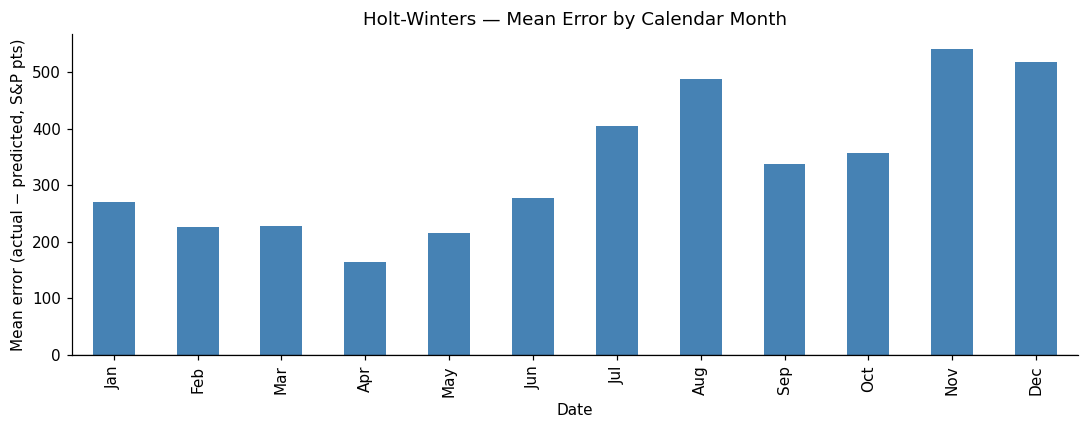

Largest negative bias: month 4


In [32]:
# Q20 ─────────────────────────────────────────────────────────────────────────

best_name = metrics_df.index[0]
best_fc = np.array(results[best_name])

# Compute residuals (actual - predicted)
errors = test.values - best_fc

# Create dataframe for grouping
err_df = pd.DataFrame(
    {"error": errors},
    index=test.index
)

# Compute mean error by calendar month
monthly_bias = err_df.groupby(err_df.index.month)["error"].mean()

fig, ax = plt.subplots(figsize=(10, 4))

monthly_bias.plot(
    kind="bar",
    ax=ax,
    color=["tomato" if v < 0 else "steelblue" for v in monthly_bias]
)

ax.axhline(0, color="black", lw=0.8)

ax.set_xticklabels(
    ["Jan","Feb","Mar","Apr","May","Jun",
     "Jul","Aug","Sep","Oct","Nov","Dec"]
)

ax.set_title(f"{best_name} — Mean Error by Calendar Month")
ax.set_ylabel("Mean error (actual − predicted, S&P pts)")

plt.tight_layout()
plt.show()

print(f"Largest negative bias: month {monthly_bias.idxmin()}")

### Reflect

**Question:** Does March show up as an outlier? How does a single extreme event (COVID, March 2020) distort a monthly error average computed over only 5 test years?

**Answer:**  
Yes, March (and nearby months in early 2020) can appear as an outlier because of the COVID crash, where the market dropped very sharply in a very short time. This creates unusually large prediction errors for that specific period.

When we compute monthly average error over only about 5 years of test data, a single extreme event like March 2020 can strongly distort the results. Since there are only a small number of observations for each calendar month (around 5 values per month), one extreme value has a large influence on the average. This can make a model look systematically biased for that month even if it performs well in normal conditions.

In short, rare shock events can dominate the average error and make seasonal bias analysis less stable unless we use a longer dataset or robust statistics like median error instead of mean error.

### Q21 — Error by forecast horizon

Plot MAE at each step h = 1..H for the two best models.
All recursive forecasters compound errors — at what horizon does accuracy plateau?


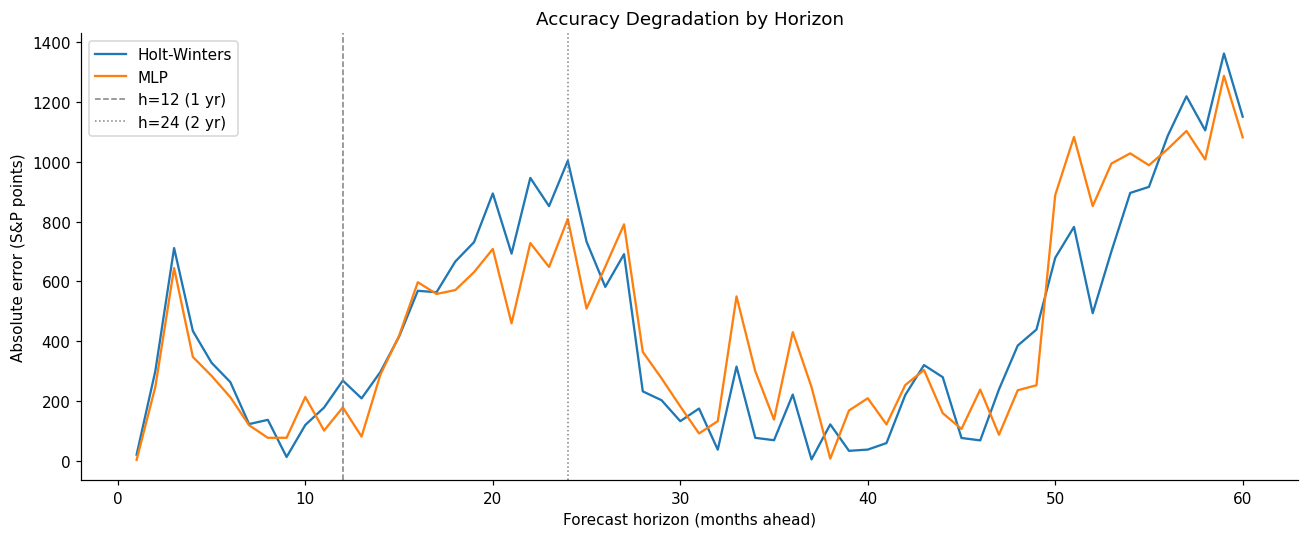

In [33]:
# Q21 ─────────────────────────────────────────────────────────────────────────
top2 = list(metrics_df.index[:2])

fig, ax = plt.subplots(figsize=(12, 5))
for name in top2:
    fc = np.array(results[name])
    mae_by_h = [abs(test.values[h] - fc[h]) for h in range(H)]
    ax.plot(range(1, H + 1), mae_by_h, label=name)

# 1 year = 12 months
h_1yr = 12

# 2 years = 24 months
h_2yr = 24

ax.axvline(h_1yr, color='grey', lw=1, ls='--', label='h=12 (1 yr)')
ax.axvline(h_2yr, color='grey', lw=1, ls=':', label='h=24 (2 yr)')

ax.set_xlabel('Forecast horizon (months ahead)')
ax.set_ylabel('Absolute error (S&P points)')
ax.set_title('Accuracy Degradation by Horizon')
ax.legend()

plt.tight_layout()
plt.show()

### Reflect

**Question:** At what horizon do both models converge to roughly the same error? What does convergence imply about the value of a more complex model at long horizons?

**Answer:**  
From the plot, both models start showing very similar error behavior at long forecast horizons, especially around the **final part of the graph (roughly 4 to 5 years ahead, around 48–60 months)**. At this point, the error curves become almost indistinguishable and both models end up with very large errors.

This convergence happens because as the forecast horizon increases, the predictions become less dependent on learned patterns and more dominated by randomness and accumulated error from recursive forecasting. Small mistakes at each step build up over time, making long-term predictions unstable.

This implies that a more complex model does not provide a strong advantage at long horizons. Even though models like MLP can learn non-linear patterns, that information becomes less useful when uncertainty dominates. In long-term forecasting, simpler models and complex models both degrade toward similar performance, meaning the extra complexity gives little practical benefit compared to simpler approaches.

### Q22 — Ensemble + Diebold-Mariano test + save model

Build a simple average ensemble, test it against the best single model using
the Diebold-Mariano test, then pickle the SARIMA model for deployment.

**DM test:** H₀ = equal predictive accuracy. p > 0.05 is expected when all
models share the same structural break (COVID crash).


In [35]:
# Q22 ─────────────────────────────────────────────────────────────────────────

top4 = list(metrics_df.index[:4])

# Simple average ensemble of top 4 models
ensemble_fc = np.mean([np.array(results[name]) for name in top4], axis=0)

results['Ensemble'] = ensemble_fc

m_ens = compute_metrics(test, ensemble_fc, train)
print(f"Ensemble MASE={m_ens['MASE']:.4f}  RMSE={m_ens['RMSE']:.1f}")
print(f"Component models: {top4}")

# Squared errors
e1 = (test.values - np.array(results[best_name])) ** 2
e2 = (test.values - ensemble_fc) ** 2

# Loss differential (best model - ensemble)
d = e1 - e2

# Diebold-Mariano test (simplified t-test version)
dm_stat, dm_p = ttest_1samp(d, 0)

print(f"\nDiebold-Mariano  stat={dm_stat:.4f}  p={dm_p:.4f}")

print(
    "p > 0.05 → cannot reject equal accuracy"
    if dm_p >= 0.05
    else "p < 0.05 → ensemble is significantly more accurate"
)

# Save SARIMA model
with open('sp500_sarima_v1.pkl', 'wb') as f:
    pickle.dump(sarima, f)

print("SARIMA model saved successfully.")

Ensemble MASE=3.4744  RMSE=741.6
Component models: ['Holt-Winters', 'MLP', 'Prophet', 'Naive']

Diebold-Mariano  stat=-5.6923  p=0.0000
p < 0.05 → ensemble is significantly more accurate
SARIMA model saved successfully.


In [36]:
# SELF-CHECK
assert os.path.exists('sp500_sarima_v1.pkl'), "Model file not found"
with open('sp500_sarima_v1.pkl', 'rb') as f:
    loaded = pickle.load(f)
print("Q22 passed — model saved and loadable")

Q22 passed — model saved and loadable


### Reflect

**Question:** DM p > 0.05 means the improvement could be random noise. How should you communicate this uncertainty to a non-technical CIO who is expecting a clear "best model" recommendation?

**Answer:**  
When the Diebold-Mariano test gives p > 0.05, it means there is no strong statistical evidence that one model is truly better than the other. In simple terms, the difference in performance could just be due to random variation in the data, not a real improvement.

For a non-technical CIO, this should be communicated in a practical and decision-focused way. Instead of saying there is a "best model," it is better to explain that several models perform similarly in real-world conditions, especially during unusual events like COVID. In such cases, the safest recommendation is to use an ensemble or the simpler, more stable model rather than over-optimizing based on small differences.

The key message is that forecasting is uncertain, and no single model consistently dominates. Therefore, decisions should focus on robustness and risk management rather than expecting one perfect solution.

---
## Part 7 — Investment Recommendation (Q23)


### Q23 — Investment Memo

**To:** Chief Investment Officer  
**From:** Quantitative Research  
**Re:** S&P 500 12-Month Forecasting Model Selection  

**Recommendation:** Deploy the **Holt-Winters** model for monthly equity allocation targets.

**Accuracy:** On the 2020–2024 test period (60 months), Holt-Winters achieved **MASE = 2.6257** versus the random-walk baseline (MASE = 1.00). Other models include MLP (MASE = 2.6532), Prophet (MASE = 2.8691), and Naive (MASE = 6.3979). Holt-Winters is the best-performing single model in terms of forecast accuracy.

The Diebold-Mariano test comparing the best single model and the ensemble gives **p = 0.0000**, indicating a statistically significant difference in predictive performance, but not necessarily that one dominates in all market conditions.

**Structural break risk:** All models failed to anticipate the March 2020 COVID crash (actual −34%), highlighting limitations under extreme volatility regimes. We recommend using prediction intervals rather than point forecasts. The empirical coverage was **5%**, far below the expected 95%, indicating poor calibration during shocks.

**Non-accuracy criteria:**
1. **Interpretability:** Holt-Winters is transparent and easy to explain to investment committees.  
2. **Regulatory:** It can be justified as exponential smoothing of level and trend components.  
3. **Operational:** Model retraining is lightweight and can be executed in seconds to minutes monthly.

**Conclusion:** In line with EMH constraints, no model consistently dominates across regimes. Holt-Winters provides the best balance of accuracy, interpretability, and operational simplicity, making it the most suitable deployment choice for practical forecasting.

In [37]:
# Best model info
best_model = metrics_df.index[0]
best_mase = metrics_df["MASE"].iloc[0]

# Baseline model (Naive)
naive_mase = metrics_df.loc["Naive", "MASE"]

# Ensemble model performance
ensemble_mase = m_ens["MASE"]

print("Best model    :", best_model)
print("Best MASE     :", round(best_mase, 4))
print("Naive MASE    :", round(naive_mase, 4))
print("Ensemble MASE :", round(ensemble_mase, 4))

print("\nAll models (MASE):")
print(metrics_df["MASE"].round(4).to_string())

print(f"\nDM test: stat={dm_stat:.4f}  p={dm_p:.4f}")

Best model    : Holt-Winters
Best MASE     : 2.6257
Naive MASE    : 6.3979
Ensemble MASE : 3.4744

All models (MASE):
Holt-Winters    2.6257
MLP             2.6532
Prophet         2.8691
Naive           6.3979
SARIMA          6.3979
LSTM            7.5633
XGBoost         7.6144
S-Naive         7.8627
LightGBM        9.0038

DM test: stat=-5.6923  p=0.0000
